In [1]:
import sys
from pathlib import Path
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

from src.models.pytorch_mlp import DiamondsMLP

Path('../reports/png').mkdir(parents=True, exist_ok=True)
Path('../models').mkdir(parents=True, exist_ok=True)

# Загружаем данные с пропусками из первого этапа
df = pd.read_csv('../data/raw/diamonds_with_missing.csv')
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# Заполняем пропуски для базовой подготовки
num_cols = ['carat', 'depth', 'table', 'x', 'y', 'z']
cat_cols = ['cut', 'color', 'clarity']

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

X = df.drop(columns=['price'])
y = df['price'].values

# Label Encoding для категориальных признаков (нужно для nn.Embedding)
cat_cardinalities = []
encoders = {}
X_cat = np.zeros((len(df), len(cat_cols)), dtype=np.int64)

for i, col in enumerate(cat_cols):
    le = LabelEncoder()
    X_cat[:, i] = le.fit_transform(X[col])
    encoders[col] = le
    n_classes = len(le.classes_)
    embed_dim = min(50, (n_classes + 1) // 2)
    cat_cardinalities.append((n_classes, embed_dim))

# Масштабирование числовых признаков
scaler = StandardScaler()
X_num = scaler.fit_transform(X[num_cols].values)

# Сплит на train/test
X_cat_train, X_cat_test, X_num_train, X_num_test, y_train, y_test = train_test_split(
    X_cat, X_num, y, test_size=0.2, random_state=42
)

print(f"Категориальные кардинальности (классы, размер эмбеддинга): {cat_cardinalities}")
print(f"Train shape: {X_num_train.shape}, Test shape: {X_num_test.shape}")

Категориальные кардинальности (классы, размер эмбеддинга): [(5, 3), (7, 4), (8, 4)]
Train shape: (43152, 6), Test shape: (10788, 6)


In [2]:
class DiamondsDataset(Dataset):
    def __init__(self, cat_data, num_data, targets):
        self.cat_data = torch.tensor(cat_data, dtype=torch.long)
        self.num_data = torch.tensor(num_data, dtype=torch.float32)
        self.targets = torch.tensor(targets, dtype=torch.float32)
        
    def __len__(self):
        return len(self.targets)
        
    def __getitem__(self, idx):
        return self.cat_data[idx], self.num_data[idx], self.targets[idx]

train_dataset = DiamondsDataset(X_cat_train, X_num_train, y_train)
test_dataset = DiamondsDataset(X_cat_test, X_num_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = DiamondsMLP(cat_cardinalities, num_numeric_features=len(num_cols)).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.005, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5)

epochs = 15
print(f"Начало обучения на устройстве: {device}")

for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for cat_b, num_b, target_b in train_loader:
        cat_b, num_b, target_b = cat_b.to(device), num_b.to(device), target_b.to(device)
        
        optimizer.zero_grad()
        preds = model(cat_b, num_b)
        loss = criterion(preds, target_b)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * cat_b.size(0)
        
    train_rmse = np.sqrt(train_loss / len(train_dataset))
    
    # Валидация на тесте
    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for cat_b, num_b, target_b in test_loader:
            cat_b, num_b, target_b = cat_b.to(device), num_b.to(device), target_b.to(device)
            preds = model(cat_b, num_b)
            loss = criterion(preds, target_b)
            test_loss += loss.item() * cat_b.size(0)
            
    test_rmse = np.sqrt(test_loss / len(test_dataset))
    scheduler.step(test_rmse)
    
    print(f"Epoch [{epoch+1}/{epochs}] | Train RMSE: {train_rmse:.2f} | Test RMSE: {test_rmse:.2f}")

Начало обучения на устройстве: cpu
Epoch [1/15] | Train RMSE: 5554.02 | Test RMSE: 5417.22
Epoch [2/15] | Train RMSE: 5233.81 | Test RMSE: 4949.89
Epoch [3/15] | Train RMSE: 4622.60 | Test RMSE: 4185.09
Epoch [4/15] | Train RMSE: 3806.21 | Test RMSE: 3214.02
Epoch [5/15] | Train RMSE: 2904.46 | Test RMSE: 2379.25
Epoch [6/15] | Train RMSE: 2067.95 | Test RMSE: 1647.36
Epoch [7/15] | Train RMSE: 1427.42 | Test RMSE: 940.42
Epoch [8/15] | Train RMSE: 1065.16 | Test RMSE: 763.64
Epoch [9/15] | Train RMSE: 913.39 | Test RMSE: 649.73
Epoch [10/15] | Train RMSE: 871.04 | Test RMSE: 643.95
Epoch [11/15] | Train RMSE: 870.62 | Test RMSE: 654.65
Epoch [12/15] | Train RMSE: 852.02 | Test RMSE: 672.38
Epoch [13/15] | Train RMSE: 855.36 | Test RMSE: 634.79
Epoch [14/15] | Train RMSE: 850.42 | Test RMSE: 634.41
Epoch [15/15] | Train RMSE: 851.77 | Test RMSE: 623.57


In [3]:
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for cat_b, num_b, target_b in test_loader:
        cat_b, num_b = cat_b.to(device), num_b.to(device)
        preds = model(cat_b, num_b)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(target_b.numpy())

nn_rmse = root_mean_squared_error(all_targets, all_preds)
nn_mae = mean_absolute_error(all_targets, all_preds)
nn_r2 = r2_score(all_targets, all_preds)

print("=== Метрики нейронной сети (PyTorch MLP) на Test ===")
print(f"RMSE: {nn_rmse:.2f}")
print(f"MAE:  {nn_mae:.2f}")
print(f"R^2:  {nn_r2:.4f}")

torch.save(model.state_dict(), '../models/pytorch_mlp.pt')

=== Метрики нейронной сети (PyTorch MLP) на Test ===
RMSE: 623.57
MAE:  340.05
R^2:  0.9755


c:\Users\user\Desktop\lab1_mlops\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\user\Desktop\lab1_mlops\venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\user\Desktop\lab1_mlops\venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_st

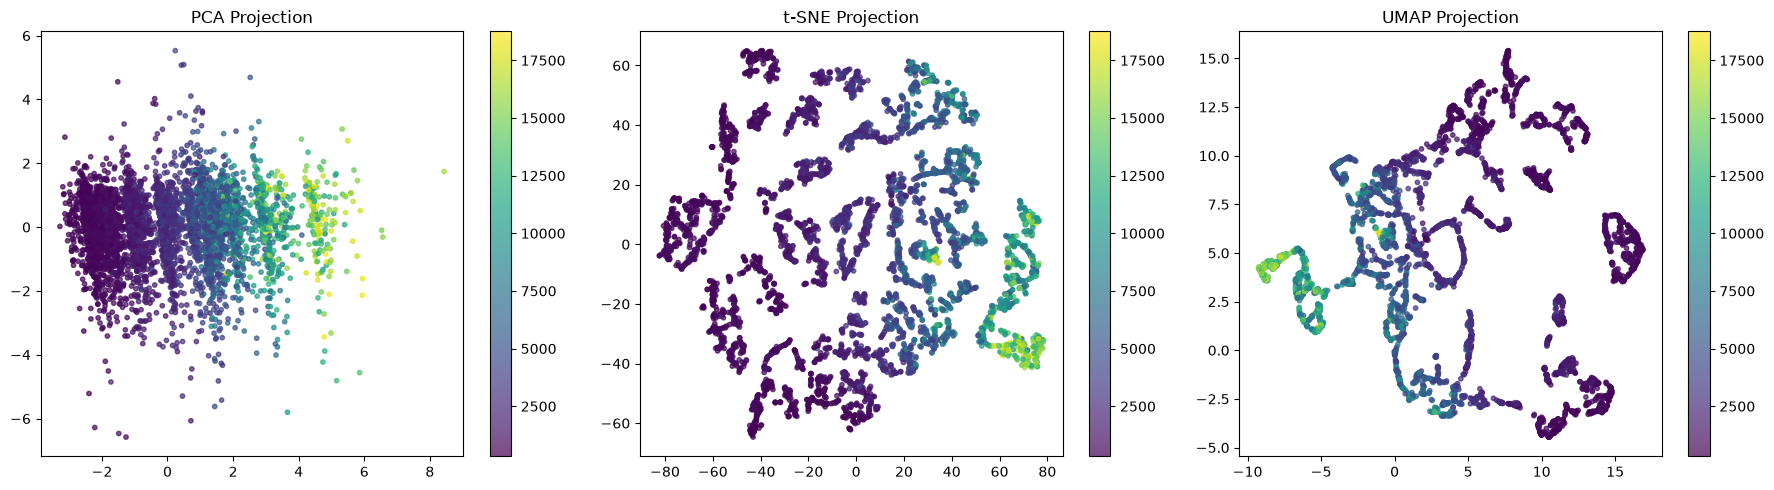

In [4]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

# Берем подвыборку для быстрой визуализации (например, 5000 точек)
sample_idx = np.random.choice(len(X_num), size=min(5000, len(X_num)), replace=False)
X_sample = X_num[sample_idx]
y_sample = y[sample_idx]

# 1. PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_sample)

# 2. t-SNE (исправлено n_iter на max_iter)
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_sample)

# 3. UMAP
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
X_umap = reducer.fit_transform(X_sample)

# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

scatter0 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_sample, cmap='viridis', s=10, alpha=0.7)
axes[0].set_title('PCA Projection')
fig.colorbar(scatter0, ax=axes[0])

scatter1 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_sample, cmap='viridis', s=10, alpha=0.7)
axes[1].set_title('t-SNE Projection')
fig.colorbar(scatter1, ax=axes[1])

scatter2 = axes[2].scatter(X_umap[:, 0], X_umap[:, 1], c=y_sample, cmap='viridis', s=10, alpha=0.7)
axes[2].set_title('UMAP Projection')
fig.colorbar(scatter2, ax=axes[2])

plt.tight_layout()
plt.savefig('../reports/png/dimensionality_reduction.png', dpi=150)
plt.show()